In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
import matplotlib.ticker as mticker
from tqdm import tqdm
from cartopy.util import add_cyclic_point


#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

### MASK 2
A mask with rectangular shape

In [2]:
if True:

    # Define the resolution
    lat_resolution = 2.5  # 2.5 degrees
    lon_resolution = 2.5  # 2.5 degrees
    
    # Define the global latitude and longitude ranges
    latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
    longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E
    
    # Initialize a global mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
    lat_min, lat_max = 60, 75
    lon_min, lon_max = -80, -20
    plon = (lon_min+lon_max)/2
    plat = (lat_min+lat_max)/2
    
    # Assign 1 to grid points within the bounding box
    for i, lat in enumerate(latitudes):
        if lat_min <= lat <= lat_max:
            for j, lon in enumerate(longitudes):
                if lon_min <= lon <= lon_max:
                    mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

In [3]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking/
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960.nc
dictionaries


In [4]:
#IMPORT DATASET
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_jja_1940-2023.nc
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc')
dic = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023_DIC.npy',allow_pickle=True)
#!cdo selmon,12,1,2 ../sfc_fluxes/latent_heat/ERA5_sfc_lat_heat_daily_northem_2.5x2.5_1940-2023.nc ../sfc_fluxes/latent_heat/ERA5_sfc_lat_heat_daily_northem_2.5x2.5_djf_1940-2023.nc
ds_comp = xr.load_dataset('../IVT/ERA5_IVT_northem_daily_2.5x2.5_1940-2023_deseasonalized.nc')
#store variables for the composite
lon = ds['lon']
lat = ds['lat']
times = ds['time']
MIX = ds['MIX_tracked']
zg = ds['zg']/9.8
#MIX = add_cyclic_point(MIX,coord=lon)
#zg,lon = add_cyclic_point(zg,coord=lon)
anom = ds_comp['IVT'] - ds_comp['IVT'].mean('time') #converted to KJ


In [5]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in range(n_iter):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [6]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = MIX.loc[:,plat,plon]
series_bool = MIX.values[:,mask_bool]
print(series_bool.shape)
list = []
counter_west = 0
list_an = []
#winter
#list_east = [4, 7, 62, 90, 93, 178, 205, 244, 282, 284, 412, 582, 731, 847, 880, 935, 968, 975, 1017, 1020, 1102, 1153, 1156, 1477, 1584, 1586, 1587, 1622, 1654, 1695, 1698, 1701, 1785, 1830, 1870, 1924, 1927, 2073, 2125, 2165, 2346, 2348, 2437, 2439, 2478, 2481, 2526, 2652, 2654, 2658, 2702, 2741, 2749, 2791, 2881, 2912, 3029, 3033, 3160, 3161, 3207, 3347, 3351, 3432, 3439]
#list_west = [27, 30, 60, 97, 176, 405, 457, 496, 583, 584, 623, 678, 725, 730, 771, 819, 821, 879, 933, 1021, 1047, 1052, 1053, 1196, 1198, 1200, 1245, 1248, 1249, 1423, 1655, 1657, 1660, 1928, 1972, 1975, 2023, 2522, 2604, 2661, 2841, 2883, 2989, 3162, 3293, 3431, 3521, 3588, 3589, 3590]#summer
#summer
list_east = [24, 63, 145, 148, 192, 332, 341, 344, 390, 393, 434, 541, 663, 708, 837, 885, 891, 935, 938, 1050, 1094, 1151, 1156, 1243, 1246, 1448, 1487, 1495, 1532, 1537, 1595, 1751, 1798, 1799, 1810, 1899, 2032, 2043, 2091, 2280, 2338, 2425, 2512, 2514, 2516, 2520, 2557, 2619, 2655, 2696, 2808, 2860, 2955, 3120, 3160, 3167, 3209, 3268, 3270, 3376, 3582, 3623, 3628, 3726, 3785, 3791, 3832, 3871, 3879, 3922, 3929, 4032, 4048, 4105, 4149]
list_west = [13, 300, 489, 534, 598, 653, 710, 791, 795, 1044, 1162, 1200, 1240, 1342, 1402, 1442, 1636, 1645, 1946, 1950, 1995, 2094, 2137, 2181, 2241, 2283, 2420, 2469, 2470, 2518, 2558, 2659, 2814, 2957, 3002, 3118, 3220, 3316, 3375, 3378, 3426, 3488, 3619, 3629, 3631, 3676, 3682, 3834, 3837, 3838, 3873, 4139, 4143]
#'''
#METHOD 1
for t,time in enumerate(times):
    if series[t] in list_west:#in list_west:
        counter_west += 1
        list.append(zg.loc[time,:,:].values)
        list_an.append(anom.loc[time,:,:].values)
#'''
'''
#METHOD2
for l in list_west:
    timing = dic[l]['time']
    persistence = dic[l]['persistence']
    for p in range(persistence):
        list.append(zg[timing+p,:,:])
        list_an.append(anom[timing+p,:,:])
'''
'''
#METHOD3
for t,time in enumerate(times):
    indexes_of_the_day = np.unique(series_bool[t])
    #print(indexes_of_the_day)
    for idx in indexes_of_the_day:
        if idx in list_west:#in list_west:
            if np.sum(MIX[t,:,:] == idx,axis=(0,1))/np.sum(mask_bool,axis=(0,1))>0.5:
                list.append(zg.loc[time,:,:].values)
                list_an.append(anom.loc[time,:,:].values)
'''
sum_t = sum(list)
sum_an = sum(list_an)
zg_comp_west = sum_t/len(list)
anom_comp_west = sum_an/len(list_an)
t_st_anom_west = abs(anom_comp_west/Bootstrap(anom,len(list_an),1000)) > 2


(30681, 175)


In [7]:
#compute the composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

series = MIX.loc[:,plat,plon]
counter_east = 0
list = []
list_an = []
#winter
#list_east = [4, 7, 62, 90, 93, 178, 205, 244, 282, 284, 412, 582, 731, 847, 880, 935, 968, 975, 1017, 1020, 1102, 1153, 1156, 1477, 1584, 1586, 1587, 1622, 1654, 1695, 1698, 1701, 1785, 1830, 1870, 1924, 1927, 2073, 2125, 2165, 2346, 2348, 2437, 2439, 2478, 2481, 2526, 2652, 2654, 2658, 2702, 2741, 2749, 2791, 2881, 2912, 3029, 3033, 3160, 3161, 3207, 3347, 3351, 3432, 3439]
#list_west = [27, 30, 60, 97, 176, 405, 457, 496, 583, 584, 623, 678, 725, 730, 771, 819, 821, 879, 933, 1021, 1047, 1052, 1053, 1196, 1198, 1200, 1245, 1248, 1249, 1423, 1655, 1657, 1660, 1928, 1972, 1975, 2023, 2522, 2604, 2661, 2841, 2883, 2989, 3162, 3293, 3431, 3521, 3588, 3589, 3590]
#summer
list_east = [24, 63, 145, 148, 192, 332, 341, 344, 390, 393, 434, 541, 663, 708, 837, 885, 891, 935, 938, 1050, 1094, 1151, 1156, 1243, 1246, 1448, 1487, 1495, 1532, 1537, 1595, 1751, 1798, 1799, 1810, 1899, 2032, 2043, 2091, 2280, 2338, 2425, 2512, 2514, 2516, 2520, 2557, 2619, 2655, 2696, 2808, 2860, 2955, 3120, 3160, 3167, 3209, 3268, 3270, 3376, 3582, 3623, 3628, 3726, 3785, 3791, 3832, 3871, 3879, 3922, 3929, 4032, 4048, 4105, 4149]
list_west = [13, 300, 489, 534, 598, 653, 710, 791, 795, 1044, 1162, 1200, 1240, 1342, 1402, 1442, 1636, 1645, 1946, 1950, 1995, 2094, 2137, 2181, 2241, 2283, 2420, 2469, 2470, 2518, 2558, 2659, 2814, 2957, 3002, 3118, 3220, 3316, 3375, 3378, 3426, 3488, 3619, 3629, 3631, 3676, 3682, 3834, 3837, 3838, 3873, 4139, 4143]
#'''
#METHOD 1
for t,time in enumerate(times):
    if series[t] in list_east:#in list_west:
        counter_east += 1
        list.append(zg.loc[time,:,:].values)
        list_an.append(anom.loc[time,:,:].values)
#'''
'''
#METHOD2
for l in list_east:
    timing = dic[l]['time']
    persistence = dic[l]['persistence']
    for p in range(persistence):
        list.append(zg[timing+p,:,:])
        list_an.append(anom[timing+p,:,:])
'''
'''
#METHOD3
for t,time in enumerate(times):
    indexes_of_the_day = np.unique(series_bool[t])
    #print(indexes_of_the_day)
    for idx in indexes_of_the_day:
        if idx in list_east:#in list_west:
            if np.sum(MIX[t,:,:] == idx,axis=(0,1))/np.sum(mask_bool,axis=(0,1))>0.5:
                list.append(zg.loc[time,:,:].values)
                list_an.append(anom.loc[time,:,:].values)
'''
sum_t = sum(list)
sum_an = sum(list_an)
zg_comp_east = sum_t/len(list)
anom_comp_east = sum_an/len(list_an)
t_st_anom_east = abs(anom_comp_east/Bootstrap(anom,len(list_an),1000)) > 2


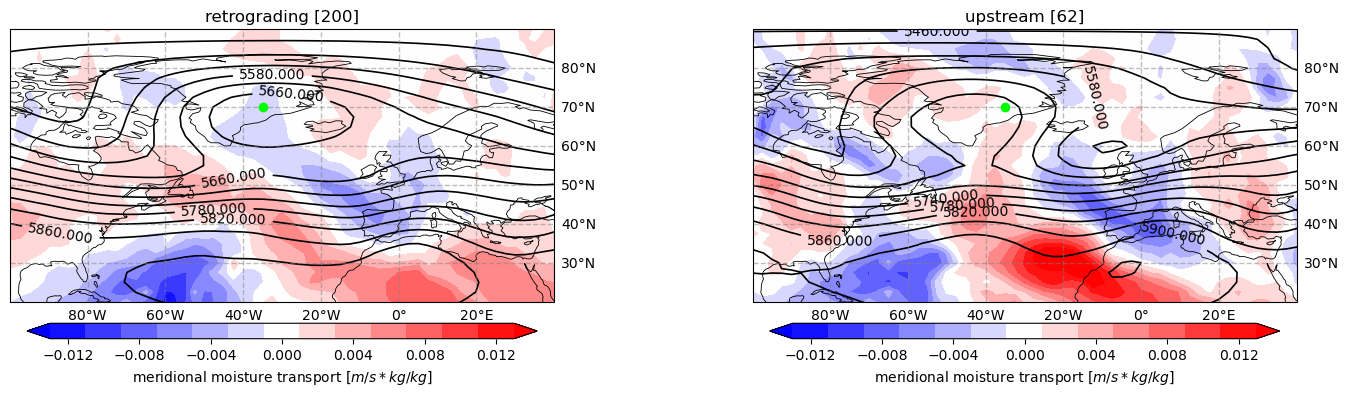

In [9]:
# Example data (you need to provide your own data for these variables)
# zg_comp, plon, plat, lon, lat, anom_comp should be defined in your script

fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(15, 4), subplot_kw={'projection': ccrs.PlateCarree()})

lon = ds['lon']
lon_comp = ds_comp['x']*2.5 - 180

titles = ['retrograding [' + str(counter_east) + ']','upstream [' + str(counter_west) + ']']
fields = [zg_comp_east,zg_comp_west]
anom_comp = [anom_comp_east,anom_comp_west]
extent = [-100, 40, 20, 90]  # Greenland
# extent =[-180,180,20,90] # Europe

for i,ax in enumerate(axarr):  # Loop over both axes
    ax.set_extent(extent, ccrs.PlateCarree())
    ax.coastlines(linewidth=0.6)
    
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=1, color='gray', alpha=0.5, linestyle='--')

    if False:
        lat_min, lat_max = 60, 80
        lon_min, lon_max = -70, -20
        # Plot the rectangle
        rect = plt.Rectangle((lon_min, lat_min), lon_max-lon_min, lat_max-lat_min,
                             edgecolor='red', facecolor='none', linewidth=2,
                             transform=ccrs.PlateCarree())
        ax.add_patch(rect)

    if True:
        ax.plot(plon,
               plat,
               marker='o',
               color='lime',
               transform=ccrs.PlateCarree())

    gl.xlabels_top = False
    gl.ylabels_left = False

    cont = ax.contour(lon, lat, fields[i],
                      colors='black',
                      alpha=1.,
                      linewidths=1.2,
                      levels=np.arange(4620, 7220, 40).astype(int))
    
    #c_range = np.array(np.arange(-np.amax(abs(anom_comp_west)), +np.amax(abs(anom_comp_west)), np.amax(abs(anom_comp_west))/8)) + np.array(np.amax(abs(anom_comp_west))/16)
    c_range = np.arange(-0.013, 0.014, 0.002)
    #ticks = np.array(np.arange(-np.amax(abs(anom_comp_west)), +np.amax(abs(anom_comp_west)), np.amax(abs(anom_comp_west))/4)) + np.array(np.amax(abs(anom_comp_west))/8)
    ticks = np.arange(-0.012, 0.014, 0.004)

    plt.clabel(cont, inline=True, fontsize=10)

    shadings = ax.contourf(lon_comp, lat, anom_comp[i],
                           cmap='bwr',
                           extend='both',
                           levels=c_range)
    fig.colorbar(shadings,label='meridional moisture transport [$m/s * kg/kg$]',orientation = "horizontal" ,ticks = ticks,fraction=0.05,pad = 0.07 ,aspect = 30,ax=ax)

for i,ax in enumerate(axarr):
    ax.set_title(titles[i])

plt.tight_layout()
#plt.savefig('/Users/michelefilippucci/PLOTS/greenland_article/summer_composite_greenland_IVT_west_multiplot.png', dpi=300)
